# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype+notebook_connected+png'

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <ArrowStringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task 1 — A line chart showing CO2 per capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

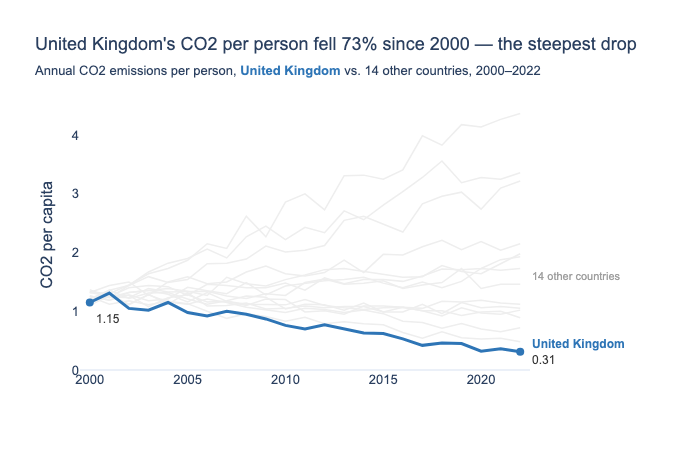

In [3]:
# Task 1 — CO2 per capita, all countries
highlight = 'United Kingdom'
data = df.sort_values('Year')
others = sorted(c for c in data['Country'].unique() if c != highlight)

trend = data[data['Country'] == highlight]
start, end = trend.iloc[0], trend.iloc[-1]
change = end['CO2_per_capita'] / start['CO2_per_capita'] - 1
latest = data[data['Year'] == data['Year'].max()].set_index('Country')['CO2_per_capita']

fig = px.line(
    data_frame=data,
    x='Year', y='CO2_per_capita',
    color='Country',
    category_orders={'Country': others + [highlight]},
    color_discrete_map={**{c: '#EEEEEE' for c in others}, highlight: '#2E75B6'},
    labels={'CO2_per_capita': 'CO2 per capita', 'Year': ''},
    template='plotly_white',
    height=450
)

fig.update_traces(line=dict(width=1.5), showlegend=False)
fig.update_traces(line=dict(width=3), selector=dict(name=highlight))

fig.add_scatter(
    x=[start['Year'], end['Year']], y=[start['CO2_per_capita'], end['CO2_per_capita']],
    mode='markers', marker=dict(color='#2E75B6', size=8),
    hoverinfo='skip', showlegend=False
)

fig.add_annotation(
    x=start['Year'], y=start['CO2_per_capita'], xanchor='left', xshift=4, yshift=-16,
    text=f"{start['CO2_per_capita']:.2f}",
    showarrow=False,
    font=dict(size=12, color='#333333')
)

fig.add_annotation(
    x=end['Year'], y=end['CO2_per_capita'], xanchor='left', xshift=10,
    text=f"<span style='color:#2E75B6'><b>{highlight}</b></span><br>{end['CO2_per_capita']:.2f}",
    showarrow=False, align='left',
    font=dict(size=12, color='#333333')
)

fig.add_annotation(
    x=end['Year'], y=latest[others].median(), xanchor='left', xshift=10,
    text=f'{len(others)} other countries',
    showarrow=False, align='left',
    font=dict(size=11, color='#9E9E9E')
)

fig.update_layout(
    title=dict(
        text=f"{highlight}'s CO2 per person fell {abs(change):.0%} since {start['Year']} — the steepest drop",
        subtitle=dict(text=(
            f"Annual CO2 emissions per person, <span style='color:#2E75B6'><b>{highlight}</b></span> vs. "
            f"{len(others)} other countries, {start['Year']}–{end['Year']}"
        ))
    ),
    font=dict(family='Arial', size=13),
    xaxis=dict(showgrid=False, dtick=5, range=[start['Year'] - 0.5, end['Year'] + 0.5]),
    yaxis=dict(showgrid=False, rangemode='tozero'),
    margin=dict(t=100, r=170)
)

fig.show()

---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**Same requirements as Task 1**

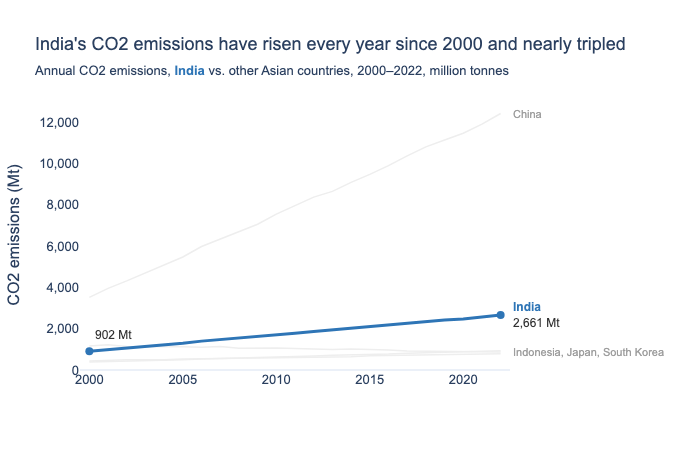

In [4]:
# Task 2 — Asian countries, CO2 emissions
highlight = 'India'
asia = df[df['Region'] == 'Asia'].sort_values('Year')
others = sorted(c for c in asia['Country'].unique() if c != highlight)

trend = asia[asia['Country'] == highlight]
start, end = trend.iloc[0], trend.iloc[-1]
latest = asia[asia['Year'] == asia['Year'].max()].set_index('Country')['CO2_Mt']
small = [c for c in others if latest[c] < end['CO2_Mt']]
large = [c for c in others if latest[c] > end['CO2_Mt']]

fig = px.line(
    data_frame=asia,
    x='Year', y='CO2_Mt',
    color='Country',
    category_orders={'Country': others + [highlight]},
    color_discrete_map={**{c: '#EEEEEE' for c in others}, highlight: '#2E75B6'},
    labels={'CO2_Mt': 'CO2 emissions (Mt)', 'Year': ''},
    template='plotly_white',
    height=450
)

fig.update_traces(line=dict(width=1.5), showlegend=False)
fig.update_traces(line=dict(width=3), selector=dict(name=highlight))

fig.add_scatter(
    x=[start['Year'], end['Year']], y=[start['CO2_Mt'], end['CO2_Mt']],
    mode='markers', marker=dict(color='#2E75B6', size=8),
    hoverinfo='skip', showlegend=False
)

fig.add_annotation(
    x=start['Year'], y=start['CO2_Mt'], xanchor='left', xshift=4, yshift=16,
    text=f"{start['CO2_Mt']:,.0f} Mt",
    showarrow=False,
    font=dict(size=12, color='#333333')
)

fig.add_annotation(
    x=end['Year'], y=end['CO2_Mt'], xanchor='left', xshift=10,
    text=f"<span style='color:#2E75B6'><b>{highlight}</b></span><br>{end['CO2_Mt']:,.0f} Mt",
    showarrow=False, align='left',
    font=dict(size=12, color='#333333')
)

for group in [large, small]:
    fig.add_annotation(
        x=end['Year'], y=latest[group].mean(), xanchor='left', xshift=10,
        text=', '.join(group),
        showarrow=False, align='left',
        font=dict(size=11, color='#9E9E9E')
    )

fig.update_layout(
    title=dict(
        text=f"{highlight}'s CO2 emissions have risen every year since {start['Year']} and nearly tripled",
        subtitle=dict(text=(
            f"Annual CO2 emissions, <span style='color:#2E75B6'><b>{highlight}</b></span> vs. other Asian countries, "
            f"{start['Year']}–{end['Year']}, million tonnes"
        ))
    ),
    font=dict(family='Arial', size=13),
    xaxis=dict(showgrid=False, dtick=5, range=[start['Year'] - 0.5, end['Year'] + 0.5]),
    yaxis=dict(showgrid=False, rangemode='tozero', tickformat=','),
    margin=dict(t=100, r=190)
)

fig.show()
